# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 2: Red neuronal con dos capas ocultas

**Grupo:** 2

**Integrantes:**
- Alondra Estay
- Gaspar Galaz
- José Mora
- Renato Reyes

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). 
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)   # aquí se guardan las figuras para el informe

Matplotlib is building the font cache; this may take a moment.


## Datos

Los archivos `datos_P2.csv` (partes (c) a (f)) y `datos_P2_g.csv` (parte (g)) deben estar en la misma carpeta que este notebook. Tienen una línea de encabezado `x,y` y dos columnas separadas por comas.

N = 200 datos;  x en [-0.990, 0.966],  y en [-0.077, 2.216]


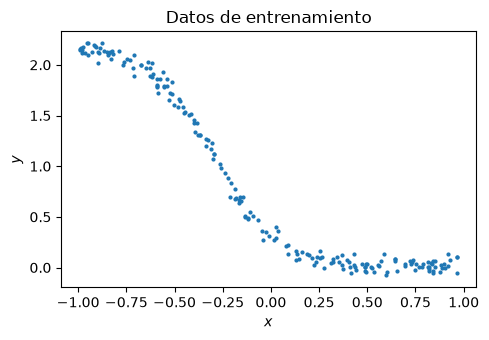

In [3]:
x, y = np.loadtxt("datos_P2.csv", delimiter=",", skiprows=1, unpack=True)
x_g, y_g = np.loadtxt("datos_P2_g.csv", delimiter=",", skiprows=1, unpack=True)
N = len(x)
print(f"N = {N} datos;  x en [{x.min():.3f}, {x.max():.3f}],  y en [{y.min():.3f}, {y.max():.3f}]")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, y, ".", ms=4)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Datos de entrenamiento")
fig.tight_layout()
fig.savefig("figuras/datos_P2.png", dpi=200)
plt.show()

## Notación

Los parámetros se agrupan, en este orden, en el vector $\theta = (a_1, b_1, a_2, b_2, v, c) \in \mathbb{R}^6$.

## (a) 

$$
\sigma(t)=\frac{1}{1+e^{-t}} = (1+e^{-t})^{-1}
$$
**derivamos con regla de la cadena:**
$$
\sigma'(t)=-(1+e^{-t})^{-2}(-e^{-t}) = \frac{e^{-t}}{(1+e^{-t})^{2}}
$$
**comprobamos si se satisface σ′(t) = σ(t)(1 − σ(t))**
$$
\sigma(t)(1-\sigma(t))\;=\; (\frac{1}{1+e^{-t}})(1 - \frac{1}{1+e^{-t}}) \;=\; \frac{1}{1+e^{-t}} - \frac{1}{(1+e^{-t})^2} \;=\; \frac{1 + e^{-t} - 1}{(1+e^{-t})^2} \;=\; \frac{e^{-t}}{(1+e^{-t})^2} \;=\; \sigma'(t)
$$
**deducimos que 0 < σ′(t), debido a que:**
$$
\forall t \in \mathbb{R}, \quad (e^{-t} > 0)
$$

**Luego:**
$$
(\sigma(t) - \frac{1}{2})^2 \geq 0 \quad \Rightarrow \quad \sigma^2(t) - \sigma(t) + \frac{1}{4} \geq 0 \quad\Rightarrow\quad \sigma(t) - \sigma^2(t) \leq \frac{1}{4} \quad\Rightarrow \quad\sigma(t)(1-\sigma(t)) \leq \frac{1}{4} \quad\Rightarrow \quad \sigma'(t) \leq \frac{1}{4}
$$
**Por lo que se deduce que 0 < σ′(t) ≤ ¼**

**Para encontrar el máximo de σ′(t) podemos usar σ′′(t) = 0, por regla de la cadena tenemos que:**
$$
\sigma''(t) = \frac{-e^{-t}(1+e^{-t})^2 - 2(1+e^{-t})(-e^{-t})(e^{-t})}{(1+e^{-t})^4}=\frac{-e^{-t}(1+e^{-t})-2(-e^{-t})(e^{-t})}{(1+e^{-t})^3} = \frac{-e^{-t}-e^{-2t}+2e^{-2t}}{(1+e^{-t})^3}=\frac{e^{-2t}-e^{-t}}{(1+e^{-t})^3} = \frac{e^{-t}(e^{-t}-1)}{(1+e^{-t})^3}
$$
**Buscamos punto crítico:**
$$
\frac{e^{-t}(e^{-t}-1)}{(1+e^{-t})^3} = 0 \quad\Rightarrow\quad(e^{-t}-1) = 0 \quad\Rightarrow\quad e^{-t} = 1 \quad\Rightarrow\quad t = 0
$$
**notamos que si t > 0 → σ′′(t) < 0 y si t < 0 → σ′′(t) > 0, por lo que σ′(t) tiene un máximo en t = 0**
$$
\sigma'(0) = \frac{e^{0}}{(1+e^{0})^{2}} = \frac{1}{4}
$$


## (b)
#### **definir:**
$$ 
z_{1,i} = a_1x_i+b1, \quad h_{1,i} = \sigma(z_1,i), \quad z_{2,i}=a_2h_{1,i}+b_2, \quad h_{2,i}=\sigma(z_{2,i}), \quad \hat{y}_i=c+vh_{2,i}, \quad e_i=\hat{y}_i-y_i, \quad L_i = \frac{e^2_i}{2}\\
\sigma'(t) = \sigma(t)(1- \sigma(t))\\
\theta = (a_1, b_1, a_2, b_2, v, c)\\
L_i = \frac{e^2_i}{2}
$$
**Funcion pérdida:**
$$
J(\theta) = \frac{1}{2N}\sum_{i=1}^{N}(\hat{y}_i - y_i)^2\quad=\quad\frac{1}{2N}\sum_{i=1}^{N}(e_i)^2 = \frac{1}{N}\sum_{i=1}^{N}Li
$$
#### **6 Derivadas parciales:**

**1°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2)-y_i)^2 \quad\Rightarrow\quad\frac{\partial L_i}{\partial a_1} = (c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2)-y_i)(a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) \cdot x_i) \\= (e_i \cdot a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) \cdot x_i) = (e_i \cdot a_2\cdot v \cdot h_{2,i}(1 - h_{2,i}) \cdot h_{1,i}(1-h_{1,i}) \cdot x_i)
$$

**2°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2) -y_i)^2 \quad\Rightarrow\quad\frac{\partial L_i}{\partial b_1} = (c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2) -y_i)(a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i})) \\= e_i \cdot a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) = e_i \cdot a_2\cdot v \cdot h_{2,i}(1 - h_{2,i}) \cdot h_{1,i}(1-h_{1,i})
$$

**3°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2h_{1,i}+b_2) -y_i)^2\quad\Rightarrow\quad\frac{\partial L_i}{\partial a_2} = (c+v\sigma(a_2h_{1,i}+b_2) -y_i)(h_{1,i}\cdot v \cdot \sigma'(z_{2,i}))\\
 = (e_i \cdot h_{1,i}\cdot v \cdot \sigma'(z_{2,i})) = (e_i \cdot h_{1,i}\cdot v \cdot h_{2,i}(1-h_{2,i}))
$$

**4°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2h_{1,i}+b_2) -y_i)^2\quad\Rightarrow\quad\frac{\partial L_i}{\partial b_2} = (c+v\sigma(a_2h_{1,i}+b_2)-y_i)(v \cdot \sigma'(z_{2,i}))\\=(e_i\cdot v \cdot \sigma'(z_{2,i}))=(e_i \cdot v \cdot h_{2,i}(1-h_{2,i}))
$$

**5°**
$$
L_i = \frac{1}{2}(c+v \cdot h_{2,i} - y_i)^2 \quad\Rightarrow\quad \frac{\partial L_i}{\partial v} = ((c+v \cdot h_{2,i} - y_i)h_{2,i})\;=\:(e_i \cdot h_{2,i})
$$

**6°**
$$
L_i = \frac{1}{2}(c+v \cdot h_{2,i} - y_i)^2 \quad\Rightarrow\quad \frac{\partial L_i}{\partial c} = (c+v \cdot h_{2,i} - y_i)\;=\;(e_i)
$$
**factores repetidos**
$$
\varphi _{2,i} = e_i \cdot v \cdot h_{2,i}(1-h_{2,i}) ,\quad \varphi _{1,i} = \varphi _{2,i} \cdot h_{1,i}(1-h_{1,i}) \cdot a_2
$$
**gradiente de forma completa**
$$
\nabla _\theta J(\theta) = \frac{1}{N}\sum_{i=1}^{N}   =     \begin{pmatrix}
\varphi _{1,i}x_i \\
\varphi _{1,i} \\
\varphi _{2,i}h_{1,i} \\
\varphi _{2,i} \\
e_ih_{2,i} \\
e_i
\end{pmatrix}
$$

## (c) Implementación y verificación del gradiente

In [4]:
# TODO

## (d) Descenso del gradiente

In [ ]:
# TODO

## (e) Parámetros encontrados

In [ ]:
# TODO

## (f) Sensibilidad del entrenamiento

### i. Tamaño del paso

In [ ]:
# TODO

### ii. Distintas inicializaciones

In [ ]:
# TODO

## (g) Datos de otra función

### i. Entrenamiento con `datos_P2_g.csv`

In [ ]:
# TODO

### ii.